# 05. Seed TF-IDF + 3x3 교차표 (Step 4)

목적: 성공 기업-연도 document로 TF-IDF 벡터를 학습하고, E/S/G 각 차원에 사전 정의된 seed 단어 10개씩(총 30개)의 TF-IDF 가중치를 합산하여 `(stock_code, fiscal_year)` 단위 3차원 텍스트 피처를 만든다.

핵심 설계:
- **L2 정규화 벡터** 사용 -> 문서 길이의 mechanical 효과 차단
- `seed_dictionary.csv`의 seed 30개를 TF-IDF vocabulary에 맞게 재토큰화 후 차원별 합산
- 3x3 (`E/S/G_text` x `E/S/G_grade`) Spearman rho 교차표로 수렴타당도 검증

프로젝트 반영 사항:
- 전처리 산출물 `dart_preprocessed.csv`는 `회사이름`, `esg_year`, `kiwi_text`만 포함한다.
- 본 노트북에서 `company_master.csv`를 `company_name + esg_year`로 엄격 merge해 `stock_code`, `fiscal_year`를 복원한다.
- 최종 PK와 등급 merge 기준은 `stock_code x fiscal_year`이다.


## 1. import 및 경로 설정

이 노트북은 `seaborn`(heatmap), `pyarrow`(parquet 저장), `statsmodels`(회귀분석)가 필요하다. 현재 프로젝트 의존성에 없으면 아래 주석의 명령으로 설치한 뒤 다시 실행한다.


In [3]:
# 필요 패키지 미설치 시 터미널에서 실행:
# uv add seaborn pyarrow statsmodels

import re
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager, rcParams
from scipy.stats import spearmanr
from sklearn.feature_extraction.text import TfidfVectorizer
from kiwipiepy import Kiwi

try:
    import seaborn as sns
except ImportError as exc:
    raise ImportError(
        "seaborn이 설치되어 있지 않습니다. 히트맵 생성을 위해 `uv add seaborn pyarrow statsmodels` 실행 후 "
        "노트북을 다시 실행하세요."
    ) from exc

try:
    import pyarrow  # noqa: F401
except ImportError as exc:
    raise ImportError(
        "pyarrow가 설치되어 있지 않습니다. parquet 저장을 위해 `uv add seaborn pyarrow statsmodels` 실행 후 "
        "노트북을 다시 실행하세요."
    ) from exc

try:
    import statsmodels.api as sm
    from statsmodels.miscmodels.ordinal_model import OrderedModel
except ImportError as exc:
    raise ImportError(
        "statsmodels가 설치되어 있지 않습니다. OLS/Binary Logit/Ordered Logit 실행을 위해 "
        "`uv add statsmodels` 또는 `uv add seaborn pyarrow statsmodels` 실행 후 노트북을 다시 실행하세요."
    ) from exc

warnings.filterwarnings('ignore')

# 한글 폰트 자동 선택
available_fonts = {font.name for font in font_manager.fontManager.ttflist}
for font_name in ['AppleGothic', 'NanumGothic', 'Malgun Gothic']:
    if font_name in available_fonts:
        rcParams['font.family'] = font_name
        break
rcParams['axes.unicode_minus'] = False

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_RAW = PROJECT_ROOT / 'data' / 'raw'
DATA_PROCESSED = PROJECT_ROOT / 'data' / 'processed'
REPORTS_DIR = PROJECT_ROOT / 'reports'
FIGURES_DIR = REPORTS_DIR / 'figures'

PREPROCESSED_CSV = DATA_PROCESSED / 'dart_preprocessed.csv'
SEED_DICTIONARY_CSV = DATA_RAW / 'seed_dictionary.csv'
COMPANY_MASTER_CSV = DATA_RAW / 'company_master.csv'
STOPWORDS_PATH = DATA_RAW / 'stopwords_ko_esg.txt'

OUTPUT_FEATURES = DATA_PROCESSED / '05_tfidf_seed_features.parquet'
OUTPUT_RHO = DATA_PROCESSED / '05_tfidf_seed_rho_matrix.csv'
OUTPUT_PVAL = DATA_PROCESSED / '05_tfidf_seed_pval_matrix.csv'
OUTPUT_HEATMAP = FIGURES_DIR / '05_tfidf_seed_spearman_heatmap.png'
OUTPUT_REGRESSION_SUMMARY = DATA_PROCESSED / '05_tfidf_seed_regression_summary.csv'
OUTPUT_OLS_SUMMARY = DATA_PROCESSED / '05_tfidf_seed_ols_summary.txt'
OUTPUT_BINARY_LOGIT_SUMMARY = DATA_PROCESSED / '05_tfidf_seed_binary_logit_summary.txt'
OUTPUT_ORDERED_LOGIT_SUMMARY = DATA_PROCESSED / '05_tfidf_seed_ordered_logit_summary.txt'

for path in [PREPROCESSED_CSV, SEED_DICTIONARY_CSV, COMPANY_MASTER_CSV, STOPWORDS_PATH]:
    assert path.exists(), f'필수 입력 파일 누락: {path}'

FIGURES_DIR.mkdir(parents=True, exist_ok=True)

print('PROJECT_ROOT:', PROJECT_ROOT)
print('전처리 입력:', PREPROCESSED_CSV)
print('seed dictionary:', SEED_DICTIONARY_CSV)
print('company master:', COMPANY_MASTER_CSV)
print('출력 features:', OUTPUT_FEATURES)
print('출력 heatmap:', OUTPUT_HEATMAP)


PROJECT_ROOT: /Users/home1/esg-dart-project
전처리 입력: /Users/home1/esg-dart-project/data/processed/dart_preprocessed.csv
seed dictionary: /Users/home1/esg-dart-project/data/raw/seed_dictionary.csv
company master: /Users/home1/esg-dart-project/data/raw/company_master.csv
출력 features: /Users/home1/esg-dart-project/data/processed/05_tfidf_seed_features.parquet
출력 heatmap: /Users/home1/esg-dart-project/reports/figures/05_tfidf_seed_spearman_heatmap.png


## 2. 분석 파라미터

TF-IDF와 등급 숫자화 규칙을 한곳에 모아 둔다. 등급은 README 작업 흐름의 `S=6 ... D=0` 기준을 따른다.


In [4]:
ESG_DIMS = ['E', 'S', 'G']

TFIDF_MIN_DF = 2
TFIDF_MAX_DF = 0.95
TFIDF_NORM = 'l2'

GRADE_MAP = {
    'S': 6,
    'A+': 5,
    'A': 4,
    'B+': 3,
    'B': 2,
    'C': 1,
    'D': 0,
}

KEY_COLS = ['stock_code', 'fiscal_year']
STRICT_KEY_COLS = ['stock_code', 'fiscal_year', 'esg_year']
TEXT_COLS = ['tfidf_E', 'tfidf_S', 'tfidf_G']
GRADE_NUM_COLS = ['e_grade_num', 's_grade_num', 'g_grade_num']
INTEGRATED_GRADE_NUM_COL = 'esg_grade_num'
HIGH_ESG_CUTOFF = 4
REGRESSION_FEATURES = TEXT_COLS

print('TF-IDF norm:', TFIDF_NORM)
print('등급 매핑:', GRADE_MAP)


TF-IDF norm: l2
등급 매핑: {'S': 6, 'A+': 5, 'A': 4, 'B+': 3, 'B': 2, 'C': 1, 'D': 0}


## 3. 전처리 코퍼스 로드 및 키 복원

`dart_preprocessed.csv`는 03 산출물 그대로 사용한다. 이 파일에 없는 `stock_code`, `fiscal_year`는 `company_master.csv`에서 `company_name + esg_year` 유일성을 확인한 뒤 복원한다.


In [5]:
preprocessed = pd.read_csv(PREPROCESSED_CSV)
master = pd.read_csv(COMPANY_MASTER_CSV, dtype={'stock_code': 'string'})

required_preprocessed_cols = {'회사이름', 'esg_year', 'kiwi_text'}
required_master_cols = {
    'company_name', 'stock_code', 'fiscal_year', 'esg_year',
    'esg_grade', 'e_grade', 's_grade', 'g_grade'
}
assert required_preprocessed_cols <= set(preprocessed.columns), (
    f'전처리 CSV 필수 컬럼 누락: {required_preprocessed_cols - set(preprocessed.columns)}'
)
assert required_master_cols <= set(master.columns), (
    f'company_master 필수 컬럼 누락: {required_master_cols - set(master.columns)}'
)

preprocessed = preprocessed.rename(columns={'회사이름': 'company_name'}).copy()
preprocessed['company_name'] = preprocessed['company_name'].astype(str).str.strip()
preprocessed['esg_year'] = preprocessed['esg_year'].astype(int)

assert preprocessed['kiwi_text'].notna().all(), 'kiwi_text 결측이 있습니다.'
preprocessed['kiwi_text'] = preprocessed['kiwi_text'].astype(str)
assert preprocessed['kiwi_text'].str.strip().ne('').all(), 'kiwi_text 빈 문자열 행이 있습니다.'
assert preprocessed.duplicated(['company_name', 'esg_year']).sum() == 0, (
    '전처리 CSV의 company_name + esg_year 중복이 있습니다.'
)

master['company_name'] = master['company_name'].astype(str).str.strip()
master['stock_code'] = (
    master['stock_code'].astype('string').str.replace(r'\.0$', '', regex=True).str.zfill(6)
)
master['fiscal_year'] = master['fiscal_year'].astype(int)
master['esg_year'] = master['esg_year'].astype(int)

assert master.duplicated(['company_name', 'esg_year']).sum() == 0, (
    'company_master의 company_name + esg_year 중복이 있어 05에서 엄격 키 복원이 불가능합니다.'
)
assert master.duplicated(KEY_COLS).sum() == 0, 'company_master의 stock_code + fiscal_year 중복이 있습니다.'

master_key_cols = [
    'company_name', 'stock_code', 'fiscal_year', 'esg_year',
    'esg_grade', 'e_grade', 's_grade', 'g_grade'
]
corpus_df = preprocessed.merge(
    master[master_key_cols],
    on=['company_name', 'esg_year'],
    how='left',
    validate='one_to_one',
    indicator=True,
)

missing_key_rows = corpus_df.loc[corpus_df['_merge'] != 'both', ['company_name', 'esg_year']]
assert missing_key_rows.empty, 'company_master에서 키를 복원하지 못한 행이 있습니다:\n' + missing_key_rows.to_string(index=False)
corpus_df = corpus_df.drop(columns=['_merge']).sort_values(KEY_COLS).reset_index(drop=True)

assert len(corpus_df) == len(preprocessed), '키 복원 후 행 수가 달라졌습니다.'
assert corpus_df[STRICT_KEY_COLS].notna().all().all(), '복원된 키에 결측이 있습니다.'
assert corpus_df.duplicated(KEY_COLS).sum() == 0, '복원 후 stock_code + fiscal_year 중복이 있습니다.'
assert corpus_df['kiwi_text'].str.strip().ne('').all(), '키 복원 후 kiwi_text 빈 문자열 행이 있습니다.'

print('코퍼스 shape:', corpus_df.shape)
print('PK 중복 수:', corpus_df.duplicated(KEY_COLS).sum())
print('kiwi_text 결측 수:', corpus_df['kiwi_text'].isna().sum())
display(corpus_df[['company_name', 'stock_code', 'fiscal_year', 'esg_year', 'kiwi_text']].head())


코퍼스 shape: (381, 11)
PK 중복 수: 0
kiwi_text 결측 수: 0


,company_name,stock_code,fiscal_year,esg_year,kiwi_text
0,동화약품,000020,2022,2023,개요 일반 지배 기업 실체 재화 용역 근거 구분 정보 내부 목적 활용 제약 의료 기...
1,동화약품,000020,2023,2024,개요 일반 지배 기업 실체 재화 용역 근거 구분 정보 내부 목적 활용 제약 의료 기...
2,동화약품,000020,2024,2025,개요 일반 지배 기업 실체 재화 용역 근거 구분 정보 내부 목적 활용 제약 의료 기...
3,KR모터스,000040,2022,2023,개요 업계 수출 주력 유럽 경기 배기량 침체 지속 가운데 배기량 스쿠터 선호도 아시...
4,KR모터스,000040,2023,2024,개요 업계 수출 주력 유럽 경기 배기량 침체 지속 가운데 배기량 스쿠터 선호도 아시...


## 4. TF-IDF 벡터 학습

`kiwi_text`는 이미 공백 구분 토큰 문자열이므로 `tokenizer=str.split`을 사용한다. `norm='l2'`를 고정해 문서 길이의 기계적 효과를 줄인다.


In [6]:
corpus_texts = corpus_df['kiwi_text'].tolist()

vectorizer = TfidfVectorizer(
    tokenizer=str.split,
    token_pattern=None,
    preprocessor=None,
    lowercase=False,
    norm=TFIDF_NORM,
    sublinear_tf=False,
    min_df=TFIDF_MIN_DF,
    max_df=TFIDF_MAX_DF,
)

X = vectorizer.fit_transform(corpus_texts)
vocab = vectorizer.get_feature_names_out()
vocab_to_idx = {term: idx for idx, term in enumerate(vocab)}

density = X.nnz / (X.shape[0] * X.shape[1])
print('TF-IDF matrix shape:', X.shape)
print('vocab size:', len(vocab))
print(f'density: {density:.6f}')
print('샘플 vocab:', vocab[:20])


TF-IDF matrix shape: (381, 40101)
vocab size: 40101
density: 0.043027
샘플 vocab: ['aa' 'aaa' 'aaai' 'aac' 'aachen' 'aacr' 'aaf' 'aaji' 'aak' 'aalto' 'aam'
 'aap' 'aaps' 'aasld' 'ab' 'abadi' 'abang' 'abb' 'abbott' 'abbvie']


## 5. L2 정규화 검증

각 문서 벡터의 L2 norm이 1인지 확인한다. 모든 문서에 TF-IDF vocabulary에 남은 토큰이 있어야 이 검증이 통과한다.


In [7]:
row_norms = np.sqrt(X.power(2).sum(axis=1)).A1
bad_norm_mask = ~np.isclose(row_norms, 1.0)

print(pd.Series(row_norms).describe().to_string())
if bad_norm_mask.any():
    display(corpus_df.loc[bad_norm_mask, ['company_name', 'stock_code', 'fiscal_year', 'esg_year']].head())

assert np.allclose(row_norms, 1.0), 'L2 정규화 sanity check 실패: 일부 문서 벡터 norm이 1이 아닙니다.'
print('L2 정규화 검증 통과:', np.allclose(row_norms, 1.0))


count    3.810000e+02
mean     1.000000e+00
std      2.549381e-15
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
L2 정규화 검증 통과: True


## 6. Seed dictionary 로드 및 TF-IDF vocab 매칭

`seed_term`과 `pattern`을 모두 사용한다. 각 phrase는 정규화, compact term 생성, 구분자 분해, Kiwi 토큰화를 거쳐 TF-IDF vocabulary와 맞춘다.


In [8]:
seed_dictionary = pd.read_csv(SEED_DICTIONARY_CSV)
assert {'dimension', 'seed_term', 'pattern'} <= set(seed_dictionary.columns), 'seed_dictionary 필수 컬럼 누락'
assert len(seed_dictionary) == 30, f'seed_dictionary는 30행이어야 합니다. 현재: {len(seed_dictionary)}'
assert seed_dictionary.groupby('dimension').size().to_dict() == {'E': 10, 'G': 10, 'S': 10}, (
    'seed_dictionary는 E/S/G 각 10개여야 합니다.'
)

with STOPWORDS_PATH.open('r', encoding='utf-8') as f:
    stopwords = {
        unicodedata.normalize('NFKC', line.strip()).lower()
        for line in f
        if line.strip() and not line.strip().startswith('#')
    }
stopwords |= {'i', 'ii', 'iii', 'iv', 'v', 'vi', 'vii', 'viii', 'ix', 'x', 'xi', 'xii'}

kiwi = Kiwi()
KEEP_POS_PREFIXES = ('N', 'V')
KEEP_POS_TAGS = {'SL'}
TOKEN_RE = re.compile(r'^[가-힣A-Za-z]+$')


def normalize_word(word: object) -> str:
    return unicodedata.normalize('NFKC', str(word)).lower().strip()


def tokenize_seed_phrase(phrase: object) -> list[str]:
    if not isinstance(phrase, str) or not phrase.strip():
        return []

    phrase = normalize_word(phrase)
    out: set[str] = set()

    compact = re.sub(r'[^가-힣A-Za-z]+', '', phrase)
    if len(compact) > 1 and TOKEN_RE.fullmatch(compact):
        out.add(compact)

    for part in re.split(r'[^가-힣A-Za-z]+', phrase):
        if len(part) > 1 and TOKEN_RE.fullmatch(part):
            out.add(part)

    for token in kiwi.tokenize(phrase):
        word = normalize_word(token.form)
        if len(word) <= 1 or not TOKEN_RE.fullmatch(word):
            continue
        if not (token.tag.startswith(KEEP_POS_PREFIXES) or token.tag in KEEP_POS_TAGS):
            continue
        out.add(word)

    return sorted(out)


def seed_candidate_terms(row: pd.Series) -> list[str]:
    phrases = [row['seed_term']]
    if isinstance(row.get('pattern'), str):
        phrases.extend(row['pattern'].split('|'))

    terms: list[str] = []
    for phrase in phrases:
        terms.extend(tokenize_seed_phrase(phrase))

    return sorted({term for term in terms if term not in stopwords})


seed_dictionary['candidate_terms'] = seed_dictionary.apply(seed_candidate_terms, axis=1)
seed_dictionary['found_terms'] = seed_dictionary['candidate_terms'].map(
    lambda terms: [term for term in terms if term in vocab_to_idx]
)
seed_dictionary['missing_terms'] = seed_dictionary['candidate_terms'].map(
    lambda terms: [term for term in terms if term not in vocab_to_idx]
)
seed_dictionary['matched_vocab_count'] = seed_dictionary['found_terms'].map(len)

seed_match_report = seed_dictionary[
    ['dimension', 'seed_term', 'pattern', 'candidate_terms', 'found_terms', 'missing_terms', 'matched_vocab_count']
].copy()

found_by_dim = {
    dim: sorted({term for terms in seed_dictionary.loc[seed_dictionary['dimension'] == dim, 'found_terms'] for term in terms})
    for dim in ESG_DIMS
}
missing_by_dim = {
    dim: sorted({term for terms in seed_dictionary.loc[seed_dictionary['dimension'] == dim, 'missing_terms'] for term in terms})
    for dim in ESG_DIMS
}

print('dimension별 vocab 매칭 term 수:', {dim: len(terms) for dim, terms in found_by_dim.items()})
print('dimension별 missing term:', missing_by_dim)

missing_seed_rows = seed_match_report[seed_match_report['matched_vocab_count'] == 0]
if not missing_seed_rows.empty:
    print('경고: vocab에 매칭되는 term이 하나도 없는 seed가 있습니다. 해당 seed는 0점 처리됩니다.')
    display(missing_seed_rows)

display(seed_match_report)


dimension별 vocab 매칭 term 수: {'E': 20, 'S': 14, 'G': 11}
dimension별 missing term: {'E': ['ghg', 'renewableenergy', '물관리', '자원순환', '재생에너지', '전력사용량', '탄소중립'], 'S': ['supplychain', '교육', '교육훈련', '근로자', '사회', '산업', '산업재해', '재해율', '중대재해', '지역사회', '직원'], 'G': ['anticorruption', 'corruption', 'ethic', 'independence', 'voting', 'votingrights', '감사', '독립', '독립성', '반부패', '부패방지', '사외', '사외이사', '사회', '위원회', '의결', '이사', '이사회', '주주', '준법', '컴플라이언스']}
경고: vocab에 매칭되는 term이 하나도 없는 seed가 있습니다. 해당 seed는 0점 처리됩니다.


,dimension,seed_term,pattern,candidate_terms,found_terms,missing_terms,matched_vocab_count
20,G,이사회,이사회,"[사회, 이사회]",[],"[사회, 이사회]",0
21,G,사외이사,사외이사,"[사외, 사외이사, 이사]",[],"[사외, 사외이사, 이사]",0
23,G,독립성,독립성|independence,"[independence, 독립, 독립성]",[],"[independence, 독립, 독립성]",0
28,G,주주,주주,[주주],[],[주주],0


,dimension,seed_term,pattern,candidate_terms,found_terms,missing_terms,matched_vocab_count
0,E,탄소,탄소,[탄소],[탄소],[],1
1,E,온실가스,온실가스|GHG,"[ghg, 온실가스]",[온실가스],[ghg],1
2,E,탄소중립,탄소중립,"[중립, 탄소, 탄소중립]","[중립, 탄소]",[탄소중립],2
3,E,넷제로,넷제로|net zero|net-zero,"[net, netzero, zero, 넷제로]","[net, netzero, zero, 넷제로]",[],4
4,E,재생에너지,재생에너지|renewable energy,"[energy, renewable, renewableenergy, 에너지, 재생, ...","[energy, renewable, 에너지, 재생]","[renewableenergy, 재생에너지]",4
5,E,에너지,에너지,[에너지],[에너지],[],1
6,E,전력,전력|전력사용량,"[사용량, 전력, 전력사용량]","[사용량, 전력]",[전력사용량],2
7,E,폐기물,폐기물,[폐기물],[폐기물],[],1
8,E,재활용,재활용|자원순환,"[순환, 자원, 자원순환, 재활용, 활용]","[순환, 자원, 재활용, 활용]",[자원순환],4
9,E,폐수,폐수|수질|물관리,"[물관리, 수질, 폐수]","[수질, 폐수]",[물관리],2


## 7. Dimension별 seed TF-IDF 합산

같은 dimension 안에서 여러 seed가 같은 vocabulary term에 매칭될 수 있으므로, dimension별로 고유 term을 만든 뒤 한 번만 합산한다.


In [9]:
def sum_seed_columns(X_sparse, vocab_index: dict[str, int], seed_words: list[str]) -> np.ndarray:
    col_indices = [vocab_index[word] for word in sorted(set(seed_words)) if word in vocab_index]
    if not col_indices:
        return np.zeros(X_sparse.shape[0], dtype=float)
    return np.asarray(X_sparse[:, col_indices].sum(axis=1)).ravel()


tfidf_scores = {
    dim: sum_seed_columns(X, vocab_to_idx, found_by_dim[dim])
    for dim in ESG_DIMS
}

for dim in ESG_DIMS:
    print(f'{dim}: matched terms={len(found_by_dim[dim])}, score mean={tfidf_scores[dim].mean():.6f}, max={tfidf_scores[dim].max():.6f}')


E: matched terms=20, score mean=0.096426, max=0.495481
S: matched terms=14, score mean=0.054287, max=0.269324
G: matched terms=11, score mean=0.028135, max=0.218621


## 8. 피처 테이블 조립 및 분포 확인

최종 피처는 `company_name`, `stock_code`, `fiscal_year`, `esg_year`와 `tfidf_E/S/G`만 포함한다. 저장 전 PK 유일성을 다시 확인한다.


,company_name,stock_code,fiscal_year,esg_year,tfidf_E,tfidf_S,tfidf_G
0,동화약품,000020,2022,2023,0.054691,0.063102,0.060448
1,동화약품,000020,2023,2024,0.050116,0.051056,0.036249
2,동화약품,000020,2024,2025,0.062979,0.053052,0.029883
3,KR모터스,000040,2022,2023,0.019509,0.023280,0.000000
4,KR모터스,000040,2023,2024,0.008182,0.029795,0.000000


,tfidf_E,tfidf_S,tfidf_G
count,381.000000,381.000000,381.000000
mean,0.096426,0.054287,0.028135
std,0.094074,0.038622,0.028719
min,0.000000,0.000000,0.000000
25%,0.025284,0.028036,0.009117
50%,0.059697,0.044996,0.021289
75%,0.143199,0.069082,0.036108
max,0.495481,0.269324,0.218621


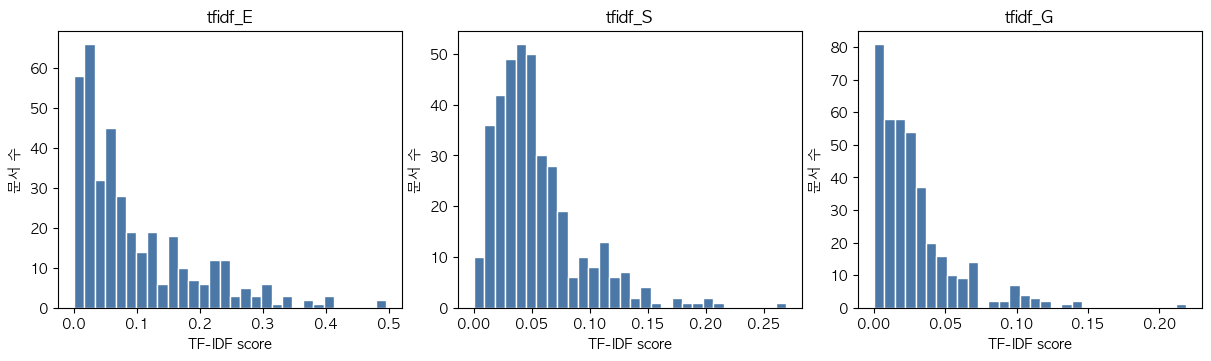

In [10]:
features = pd.DataFrame({
    'company_name': corpus_df['company_name'],
    'stock_code': corpus_df['stock_code'],
    'fiscal_year': corpus_df['fiscal_year'],
    'esg_year': corpus_df['esg_year'],
    'tfidf_E': tfidf_scores['E'],
    'tfidf_S': tfidf_scores['S'],
    'tfidf_G': tfidf_scores['G'],
})

assert len(features) == len(corpus_df), 'features 행 수가 corpus_df와 다릅니다.'
assert features[STRICT_KEY_COLS].notna().all().all(), 'features 키 컬럼에 결측이 있습니다.'
assert features.duplicated(KEY_COLS).sum() == 0, 'features의 stock_code + fiscal_year 중복이 있습니다.'
assert features[TEXT_COLS].notna().all().all(), 'TF-IDF 피처에 결측이 있습니다.'

display(features.head())
display(features[TEXT_COLS].describe())

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), constrained_layout=True)
for ax, col in zip(axes, TEXT_COLS):
    ax.hist(features[col], bins=30, color='#4C78A8', edgecolor='white')
    ax.set_title(col)
    ax.set_xlabel('TF-IDF score')
    ax.set_ylabel('문서 수')
plt.show()


## 9. ESG 등급 데이터 준비 및 merge

등급 데이터는 `company_master.csv`에서 가져온다. merge는 `stock_code + fiscal_year + esg_year` 기준으로 검증하며, 등급 문자는 숫자 서열로 변환한다.


In [11]:
grades = master[
    ['company_name', 'stock_code', 'fiscal_year', 'esg_year', 'esg_grade', 'e_grade', 's_grade', 'g_grade']
].copy()
grades = grades.sort_values(KEY_COLS).reset_index(drop=True)

for col in ['esg_grade', 'e_grade', 's_grade', 'g_grade']:
    grades[col] = grades[col].astype(str).str.strip()

grades['esg_grade_num'] = grades['esg_grade'].map(GRADE_MAP)
grades['e_grade_num'] = grades['e_grade'].map(GRADE_MAP)
grades['s_grade_num'] = grades['s_grade'].map(GRADE_MAP)
grades['g_grade_num'] = grades['g_grade'].map(GRADE_MAP)
grades['high_esg'] = (grades['esg_grade_num'] >= HIGH_ESG_CUTOFF).astype(int)

assert grades.duplicated(STRICT_KEY_COLS).sum() == 0, 'grades의 strict key 중복이 있습니다.'
assert grades['esg_grade_num'].notna().all(), '숫자화되지 않은 통합 ESG 등급이 있습니다.'
assert grades[GRADE_NUM_COLS].notna().all().all(), '숫자화되지 않은 E/S/G 등급이 있습니다.'
assert set(grades['high_esg'].dropna().unique()) == {0, 1}, 'high_esg가 0/1 두 클래스를 모두 가져야 합니다.'

merged = features.merge(
    grades[STRICT_KEY_COLS + ['esg_grade', 'e_grade', 's_grade', 'g_grade', 'esg_grade_num', 'high_esg'] + GRADE_NUM_COLS],
    on=STRICT_KEY_COLS,
    how='left',
    validate='one_to_one',
    indicator=True,
)

match_rate = (merged['_merge'] == 'both').mean()
grade_attached_rate = merged[[INTEGRATED_GRADE_NUM_COL] + GRADE_NUM_COLS].notna().all(axis=1).mean()
assert match_rate == 1.0, '등급 merge 누락 행이 있습니다.'
assert grade_attached_rate == 1.0, '통합 ESG 및 E/S/G 숫자 등급이 붙지 않은 행이 있습니다.'
assert set(merged['high_esg'].dropna().unique()) == {0, 1}, 'merged high_esg가 0/1 두 클래스를 모두 가져야 합니다.'
merged = merged.drop(columns=['_merge'])

print(f'등급 매칭률: {match_rate:.1%} ({int(match_rate * len(features))}/{len(features)})')
print(f'통합 ESG 및 E/S/G 등급 부착률: {grade_attached_rate:.1%}')
print('high_esg 분포 (A 이상=1):')
print(merged['high_esg'].value_counts().sort_index().to_string())
display(merged[['company_name', 'stock_code', 'fiscal_year', 'esg_year'] + TEXT_COLS + ['esg_grade_num', 'high_esg'] + GRADE_NUM_COLS].head())
display(merged[['esg_grade', 'e_grade', 's_grade', 'g_grade']].apply(pd.Series.value_counts).fillna(0).astype(int))


등급 매칭률: 100.0% (381/381)
통합 ESG 및 E/S/G 등급 부착률: 100.0%
high_esg 분포 (A 이상=1):
high_esg
0    229
1    152


,company_name,stock_code,fiscal_year,esg_year,tfidf_E,tfidf_S,tfidf_G,esg_grade_num,high_esg,e_grade_num,s_grade_num,g_grade_num
0,동화약품,000020,2022,2023,0.054691,0.063102,0.060448,1,0,1,2,1
1,동화약품,000020,2023,2024,0.050116,0.051056,0.036249,1,0,2,2,1
2,동화약품,000020,2024,2025,0.062979,0.053052,0.029883,1,0,2,1,1
3,KR모터스,000040,2022,2023,0.019509,0.023280,0.000000,0,0,0,0,0
4,KR모터스,000040,2023,2024,0.008182,0.029795,0.000000,0,0,0,0,0


,esg_grade,e_grade,s_grade,g_grade
A,123,130,97,85
A+,29,42,136,18
B,36,29,14,48
B+,76,74,33,99
C,53,64,34,68
D,64,42,67,63


## 10. 3x3 Spearman 교차표 계산

`tfidf_E/S/G`와 `e/s/g_grade_num`의 모든 조합에 대해 Spearman 순위상관계수와 p-value를 계산한다.


In [12]:
rho_matrix = pd.DataFrame(index=TEXT_COLS, columns=GRADE_NUM_COLS, dtype=float)
pval_matrix = pd.DataFrame(index=TEXT_COLS, columns=GRADE_NUM_COLS, dtype=float)

spearman_data = merged.dropna(subset=TEXT_COLS + GRADE_NUM_COLS).copy()
assert len(spearman_data) > 0, 'Spearman 계산 가능한 데이터가 없습니다.'

for text_col in TEXT_COLS:
    for grade_col in GRADE_NUM_COLS:
        pair = spearman_data[[text_col, grade_col]].dropna()
        if pair[text_col].nunique() < 2 or pair[grade_col].nunique() < 2:
            rho, pval = np.nan, np.nan
        else:
            rho, pval = spearmanr(pair[text_col], pair[grade_col])
        rho_matrix.loc[text_col, grade_col] = rho
        pval_matrix.loc[text_col, grade_col] = pval

print('Spearman rho matrix')
display(rho_matrix)
print('p-value matrix')
display(pval_matrix)


Spearman rho matrix


,e_grade_num,s_grade_num,g_grade_num
tfidf_E,0.358826,0.305958,0.202571
tfidf_S,0.358355,0.384942,0.352835
tfidf_G,0.421906,0.469726,0.509938


p-value matrix


,e_grade_num,s_grade_num,g_grade_num
tfidf_E,5.087856e-13,1.065292e-09,6.822370e-05
tfidf_S,5.482305e-13,6.630152e-15,1.304076e-12
tfidf_G,7.074887e-18,2.634476e-22,1.309064e-26


## 11. Spearman 교차표 heatmap

색은 rho 값을 나타내며, 각 셀 annotation에는 rho와 유의수준 별표를 함께 표기한다.


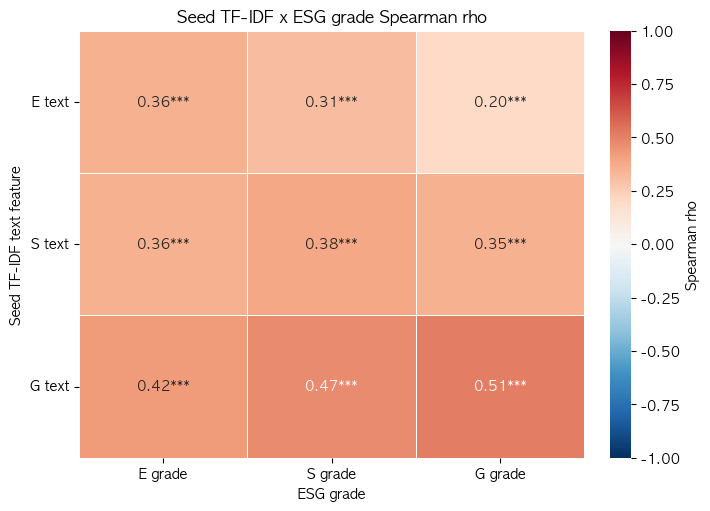

heatmap 저장: /Users/home1/esg-dart-project/reports/figures/05_tfidf_seed_spearman_heatmap.png


In [13]:
def pvalue_stars(pval: float) -> str:
    if pd.isna(pval):
        return ''
    if pval < 0.001:
        return '***'
    if pval < 0.01:
        return '**'
    if pval < 0.05:
        return '*'
    return ''


annot = rho_matrix.copy().astype(object)
for row in rho_matrix.index:
    for col in rho_matrix.columns:
        rho = rho_matrix.loc[row, col]
        pval = pval_matrix.loc[row, col]
        annot.loc[row, col] = 'NA' if pd.isna(rho) else f'{rho:.2f}{pvalue_stars(pval)}'

fig, ax = plt.subplots(figsize=(7, 5), constrained_layout=True)
sns.heatmap(
    rho_matrix.astype(float),
    annot=annot,
    fmt='',
    center=0,
    cmap='RdBu_r',
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor='white',
    cbar_kws={'label': 'Spearman rho'},
    ax=ax,
)
ax.set_title('Seed TF-IDF x ESG grade Spearman rho')
ax.set_xlabel('ESG grade')
ax.set_ylabel('Seed TF-IDF text feature')
ax.set_xticklabels(['E grade', 'S grade', 'G grade'])
ax.set_yticklabels(['E text', 'S text', 'G text'], rotation=0)

fig.savefig(OUTPUT_HEATMAP, dpi=200, bbox_inches='tight')
plt.show()

print('heatmap 저장:', OUTPUT_HEATMAP)


## 12. 해석

- **대각선이 강하고 비대각선이 약함** -> 차원별 텍스트 측정이 성공한 패턴이다. 예를 들어 E 텍스트는 E 등급과, S 텍스트는 S 등급과, G 텍스트는 G 등급과 상대적으로 더 강하게 연결된다.
- **비대각선까지 강함** -> 공시량/문서량 효과를 의심해야 한다. E/S/G 모든 텍스트 점수가 함께 커지는 경우, 특정 차원의 실질 신호가 아니라 "ESG를 많이 쓴 회사" 효과일 수 있다.
- 이 경우 이후 단계에서 Dense cosine과 비교하고, 회귀 단계에서 공시분량 통제가 필수다.
- 아래 회귀 섹션은 통제변수 없는 baseline 검증이다. fastText 확장, Dense embedding, 자산/산업 통제 회귀는 수행하지 않는다.


Seed TF-IDF 점수는 E/S/G 등급 모두와 유의한 양의 Spearman 상관을 보였다. 특히 대각선 상관은 E 0.36, S 0.38, G 0.51로 나타나 seed 기반 텍스트 feature가 ESG 평가와 일정한 수렴타당도를 갖는 것으로 보인다. 다만 비대각선 상관도 전반적으로 높아, 각 차원이 독립적으로 분리되었다기보다는 ESG 공시 전반의 충실도 또는 기업의 전반적 ESG maturity를 함께 반영하는 것으로 해석된다.

## 13. 회귀 패널 구성

통합 ESG 등급(`esg_grade_num`)을 종속변수로 두고, `tfidf_E`, `tfidf_S`, `tfidf_G`를 함께 투입한다. Binary Logit은 A 이상(`esg_grade_num >= 4`)을 우수 그룹으로 정의한다.


In [14]:
regression_panel = merged.dropna(
    subset=[INTEGRATED_GRADE_NUM_COL, 'high_esg'] + REGRESSION_FEATURES
).copy()

assert len(regression_panel) > 0, '회귀에 사용할 행이 없습니다.'
assert regression_panel[INTEGRATED_GRADE_NUM_COL].notna().all(), 'esg_grade_num 결측이 있습니다.'
assert regression_panel['high_esg'].notna().all(), 'high_esg 결측이 있습니다.'
assert set(regression_panel['high_esg'].unique()) == {0, 1}, 'Binary Logit을 위해 high_esg는 0/1 두 클래스를 모두 가져야 합니다.'
assert regression_panel[REGRESSION_FEATURES].notna().all().all(), '회귀 설명변수에 결측이 있습니다.'

print('회귀 패널 shape:', regression_panel.shape)
print('통합 ESG 등급 분포:')
print(regression_panel['esg_grade'].value_counts().sort_index().to_string())
print('\nhigh_esg 분포 (A 이상=1):')
print(regression_panel['high_esg'].value_counts().sort_index().to_string())
display(regression_panel[['company_name', 'stock_code', 'fiscal_year', 'esg_grade', 'esg_grade_num', 'high_esg'] + REGRESSION_FEATURES].head())


회귀 패널 shape: (381, 16)
통합 ESG 등급 분포:
esg_grade
A     123
A+     29
B      36
B+     76
C      53
D      64

high_esg 분포 (A 이상=1):
high_esg
0    229
1    152


,company_name,stock_code,fiscal_year,esg_grade,esg_grade_num,high_esg,tfidf_E,tfidf_S,tfidf_G
0,동화약품,000020,2022,C,1,0,0.054691,0.063102,0.060448
1,동화약품,000020,2023,C,1,0,0.050116,0.051056,0.036249
2,동화약품,000020,2024,C,1,0,0.062979,0.053052,0.029883
3,KR모터스,000040,2022,D,0,0,0.019509,0.023280,0.000000
4,KR모터스,000040,2023,D,0,0,0.008182,0.029795,0.000000


## 14. OLS 회귀분석

OLS는 통합 ESG 등급을 연속형 점수처럼 본 baseline이다. `HC3` robust standard error를 사용한다.


In [15]:
ols_X = sm.add_constant(regression_panel[REGRESSION_FEATURES], has_constant='add')
ols_y = regression_panel[INTEGRATED_GRADE_NUM_COL]

ols_result = sm.OLS(ols_y, ols_X).fit(cov_type='HC3')
print(ols_result.summary())

ols_coef_table = pd.DataFrame({
    'term': ols_result.params.index,
    'coef': ols_result.params.values,
    'std_err': ols_result.bse.values,
    'p_value': ols_result.pvalues.values,
})
ols_coef_table['model'] = 'OLS'
ols_coef_table['metric_name'] = 'r_squared'
ols_coef_table['metric_value'] = ols_result.rsquared
display(ols_coef_table)


                            OLS Regression Results                            
Dep. Variable:          esg_grade_num   R-squared:                       0.243
Model:                            OLS   Adj. R-squared:                  0.237
Method:                 Least Squares   F-statistic:                     42.41
Date:                Thu, 28 May 2026   Prob (F-statistic):           1.23e-23
Time:                        11:57:22   Log-Likelihood:                -671.74
No. Observations:                 381   AIC:                             1351.
Df Residuals:                     377   BIC:                             1367.
Df Model:                           3                                         
Covariance Type:                  HC3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          1.4417      0.138     10.430      0.0

,term,coef,std_err,p_value,model,metric_name,metric_value
0,const,1.441686,0.138228,1.813192e-25,OLS,r_squared,0.242836
1,tfidf_E,2.415290,0.782833,2.033341e-03,OLS,r_squared,0.242836
2,tfidf_S,6.892962,1.958728,4.330125e-04,OLS,r_squared,0.242836
3,tfidf_G,19.535968,2.816558,4.030334e-12,OLS,r_squared,0.242836


통제변수 없이 텍스트 seed 3개만으로 통합 ESG 등급 변동의 약 24%를 설명

## 15. Binary Logit 회귀분석

Binary Logit은 A 이상 여부(`high_esg`)를 종속변수로 둔다. 계수와 함께 odds ratio를 출력한다.


In [16]:
binary_X = sm.add_constant(regression_panel[REGRESSION_FEATURES], has_constant='add')
binary_y = regression_panel['high_esg']

binary_logit_result = sm.Logit(binary_y, binary_X).fit(disp=False)
print(binary_logit_result.summary())

binary_coef_table = pd.DataFrame({
    'term': binary_logit_result.params.index,
    'coef': binary_logit_result.params.values,
    'std_err': binary_logit_result.bse.values,
    'p_value': binary_logit_result.pvalues.values,
})
binary_coef_table['odds_ratio'] = np.exp(binary_coef_table['coef'])
binary_coef_table['model'] = 'Binary Logit'
binary_coef_table['metric_name'] = 'pseudo_r_squared'
binary_coef_table['metric_value'] = binary_logit_result.prsquared
display(binary_coef_table)


                           Logit Regression Results                           
Dep. Variable:               high_esg   No. Observations:                  381
Model:                          Logit   Df Residuals:                      377
Method:                           MLE   Df Model:                            3
Date:                Thu, 28 May 2026   Pseudo R-squ.:                  0.1593
Time:                        11:57:22   Log-Likelihood:                -215.43
converged:                       True   LL-Null:                       -256.25
Covariance Type:            nonrobust   LLR p-value:                 1.355e-17
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -1.9309      0.243     -7.961      0.000      -2.406      -1.456
tfidf_E        2.6271      1.368      1.920      0.055      -0.054       5.308
tfidf_S        5.9343      3.363      1.765      0.0

,term,coef,std_err,p_value,odds_ratio,model,metric_name,metric_value
0,const,-1.930865,0.242532,1.702744e-15,1.450227e-01,Binary Logit,pseudo_r_squared,0.159324
1,tfidf_E,2.627067,1.368006,5.481215e-02,1.383314e+01,Binary Logit,pseudo_r_squared,0.159324
2,tfidf_S,5.934338,3.362563,7.759307e-02,3.777900e+02,Binary Logit,pseudo_r_squared,0.159324
3,tfidf_G,33.382177,5.655095,3.568922e-09,3.145539e+14,Binary Logit,pseudo_r_squared,0.159324


A 이상 우수 등급 여부를 설명할 때는 tfidf_G만 뚜렷하게 유의

## 16. Ordered Logit 회귀분석

Ordered Logit은 ESG 등급의 서열성을 보존한다. `OrderedModel`에는 상수항을 넣지 않는다.


In [17]:
ordered_X = regression_panel[REGRESSION_FEATURES]
ordered_y = regression_panel[INTEGRATED_GRADE_NUM_COL]

ordered_model = OrderedModel(ordered_y, ordered_X, distr='logit')
ordered_logit_result = ordered_model.fit(method='bfgs', disp=False)
print(ordered_logit_result.summary())

ordered_coef_table = pd.DataFrame({
    'term': ordered_logit_result.params.index,
    'coef': ordered_logit_result.params.values,
    'std_err': ordered_logit_result.bse.values,
    'p_value': ordered_logit_result.pvalues.values,
})
ordered_coef_table = ordered_coef_table[ordered_coef_table['term'].isin(REGRESSION_FEATURES)].copy()
ordered_coef_table['model'] = 'Ordered Logit'
ordered_coef_table['metric_name'] = 'aic'
ordered_coef_table['metric_value'] = ordered_logit_result.aic
display(ordered_coef_table)


                             OrderedModel Results                             
Dep. Variable:          esg_grade_num   Log-Likelihood:                -590.04
Model:                   OrderedModel   AIC:                             1196.
Method:            Maximum Likelihood   BIC:                             1228.
Date:                Thu, 28 May 2026                                         
Time:                        11:57:22                                         
No. Observations:                 381                                         
Df Residuals:                     373                                         
Df Model:                           3                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
tfidf_E        3.0691      1.072      2.863      0.004       0.968       5.170
tfidf_S        8.9100      2.715      3.282      0.0

,term,coef,std_err,p_value,model,metric_name,metric_value
0,tfidf_E,3.069098,1.071958,4.195476e-03,Ordered Logit,aic,1196.086201
1,tfidf_S,8.910034,2.714638,1.029939e-03,Ordered Logit,aic,1196.086201
2,tfidf_G,23.285877,3.628847,1.390949e-10,Ordered Logit,aic,1196.086201


- tfidf_E/S/G가 높을수록 통합 ESG 등급이 높은 경향이 있고, 그중 G 텍스트 점수의 설명력이 가장 강하게 나온다는 결과



세 회귀모형 모두에서 seed TF-IDF 변수는 통합 ESG 등급과 양의 관계를 보였다. OLS에서는 세 차원 모두 유의했으며, ordered logit에서도 E/S/G seed 점수가 높을수록 더 높은 ESG 등급에 속할 가능성이 유의하게 증가했다. Binary logit에서는 A 이상 우수등급 여부에 대해 G 텍스트 점수가 가장 강하고 안정적인 예측 신호를 보였다. 다만 본 모형은 통제변수 없는 baseline이므로, 결과는 인과효과가 아니라 텍스트 공시 강도와 ESG 등급 간의 연관성으로 해석해야 한다.

## 17. 회귀 결과 저장

세 모델의 핵심 계수표를 하나의 CSV로 저장하고, statsmodels 전체 summary는 모델별 텍스트 파일로 저장한다.


In [18]:
regression_summary = pd.concat(
    [ols_coef_table, binary_coef_table, ordered_coef_table],
    ignore_index=True,
    sort=False,
)
regression_summary = regression_summary[
    ['model', 'term', 'coef', 'std_err', 'p_value', 'odds_ratio', 'metric_name', 'metric_value']
]

regression_summary.to_csv(OUTPUT_REGRESSION_SUMMARY, index=False, encoding='utf-8-sig')
OUTPUT_OLS_SUMMARY.write_text(ols_result.summary().as_text(), encoding='utf-8')
OUTPUT_BINARY_LOGIT_SUMMARY.write_text(binary_logit_result.summary().as_text(), encoding='utf-8')
OUTPUT_ORDERED_LOGIT_SUMMARY.write_text(ordered_logit_result.summary().as_text(), encoding='utf-8')

for path in [OUTPUT_REGRESSION_SUMMARY, OUTPUT_OLS_SUMMARY, OUTPUT_BINARY_LOGIT_SUMMARY, OUTPUT_ORDERED_LOGIT_SUMMARY]:
    assert path.exists(), f'회귀 결과 저장 실패: {path}'
    print('회귀 결과 저장 완료:', path)

display(regression_summary)


회귀 결과 저장 완료: /Users/home1/esg-dart-project/data/processed/05_tfidf_seed_regression_summary.csv
회귀 결과 저장 완료: /Users/home1/esg-dart-project/data/processed/05_tfidf_seed_ols_summary.txt
회귀 결과 저장 완료: /Users/home1/esg-dart-project/data/processed/05_tfidf_seed_binary_logit_summary.txt
회귀 결과 저장 완료: /Users/home1/esg-dart-project/data/processed/05_tfidf_seed_ordered_logit_summary.txt


,model,term,coef,std_err,p_value,odds_ratio,metric_name,metric_value
0,OLS,const,1.441686,0.138228,1.813192e-25,NaN,r_squared,0.242836
1,OLS,tfidf_E,2.415290,0.782833,2.033341e-03,NaN,r_squared,0.242836
2,OLS,tfidf_S,6.892962,1.958728,4.330125e-04,NaN,r_squared,0.242836
3,OLS,tfidf_G,19.535968,2.816558,4.030334e-12,NaN,r_squared,0.242836
4,Binary Logit,const,-1.930865,0.242532,1.702744e-15,1.450227e-01,pseudo_r_squared,0.159324
5,Binary Logit,tfidf_E,2.627067,1.368006,5.481215e-02,1.383314e+01,pseudo_r_squared,0.159324
6,Binary Logit,tfidf_S,5.934338,3.362563,7.759307e-02,3.777900e+02,pseudo_r_squared,0.159324
7,Binary Logit,tfidf_G,33.382177,5.655095,3.568922e-09,3.145539e+14,pseudo_r_squared,0.159324
8,Ordered Logit,tfidf_E,3.069098,1.071958,4.195476e-03,NaN,aic,1196.086201
9,Ordered Logit,tfidf_S,8.910034,2.714638,1.029939e-03,NaN,aic,1196.086201


## 18. 산출물 저장

피처 테이블은 parquet로 저장하고, Spearman rho/p-value 교차표는 CSV로 저장한다. heatmap PNG는 앞 셀에서 저장했다.


In [19]:
features.to_parquet(OUTPUT_FEATURES, index=False)
rho_matrix.to_csv(OUTPUT_RHO, encoding='utf-8-sig')
pval_matrix.to_csv(OUTPUT_PVAL, encoding='utf-8-sig')

for path in [OUTPUT_FEATURES, OUTPUT_RHO, OUTPUT_PVAL, OUTPUT_HEATMAP]:
    assert path.exists(), f'저장 실패: {path}'
    print('저장 완료:', path)

print('\nfeatures shape:', features.shape)
display(features.head())


ArrowKeyError: No type extension with name arrow.py_extension_type found